# Kỹ thuật 1 — CLAHE: Cân bằng lược đồ xám thích nghi có giới hạn tương phản

**Môn học:** Thị giác máy tính (Mã môn 121036) — Trường Đại học Giao thông vận tải TP.HCM
**Tài liệu tham chiếu:** `Computer_Vision 40.pdf`, Mục 2.5 (Đặc tả cài đặt), Mục 2.6 (Thí nghiệm minh họa) & Mục 5.1 (Quy định dùng AI)

Notebook này triển khai đầy đủ các yêu cầu thí nghiệm của Kỹ thuật 1:

* **Yêu cầu (a) — Ảnh hưởng của tham số:** Quét `clip_limit` và `grid` qua ít nhất bốn giá trị cho mỗi tham số. Trình bày kết quả dưới dạng lưới ảnh. Cần lựa chọn ảnh có vùng phẳng nhiều nhiễu để bộc lộ tác dụng của `clip_limit` và ảnh có ánh sáng không đều theo vùng để bộc lộ tác dụng của `grid`.
* **Yêu cầu (b) — So sánh với thuật toán đã học:** Hiển thị đối chiếu 4 phương pháp trên cùng một ảnh: kéo giãn tương phản tuyến tính, hiệu chỉnh gamma, cân bằng lược đồ xám toàn cục (HE), và CLAHE. Các kết quả phải được đính kèm lược đồ xám (histogram) tương ứng. Phải chỉ ra được một ảnh mà CLAHE thắng rõ rệt và một ảnh mà CLAHE thua một trong ba phương pháp còn lại.

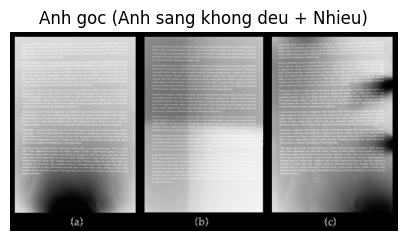

In [3]:
%matplotlib inline
import sys
import os
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from src.clahe import clip_histogram, build_tile_luts, clahe

img = plt.imread('../data/ex1.jpg')

if img.ndim == 3:
    img = (img[:, :, 0] * 255).astype(np.uint8)
else:
    img = (img * 255).astype(np.uint8) if img.max() <= 1.0 else img.astype(np.uint8)

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title('Anh goc (Anh sang khong deu + Nhieu)')
plt.axis('off')
plt.show()

## 1. Yêu cầu (a) — Ảnh hưởng của tham số

Theo Mục 2.6, thí nghiệm này khảo sát tác động của hai tham số độc lập trong cấu trúc thuật toán CLAHE:

* **Khảo sát giới hạn tương phản (`clip_limit`)**: Quét qua 4 giá trị khác nhau để kiểm tra mức độ chặn độ dốc bảng tra. Ảnh đầu vào được sử dụng phải có vùng phẳng, gần như đồng nhất và có nhiễu để quan sát rõ hiệu ứng khuếch đại nhiễu (ảnh trông bị "rỗ") khi không cắt lược đồ hợp lý.
* **Khảo sát chia ô không gian (`grid`)**: Quét qua 4 giá trị kích thước lưới phân chia ảnh (ví dụ: 2x2, 4x4, 8x8, 16x16). Ảnh đầu vào cần có đặc điểm ánh sáng không đều (như nhãn container nửa dưới nắng, nửa trong bóng) để quan sát sự thích nghi theo vùng của từng bảng tra riêng biệt.

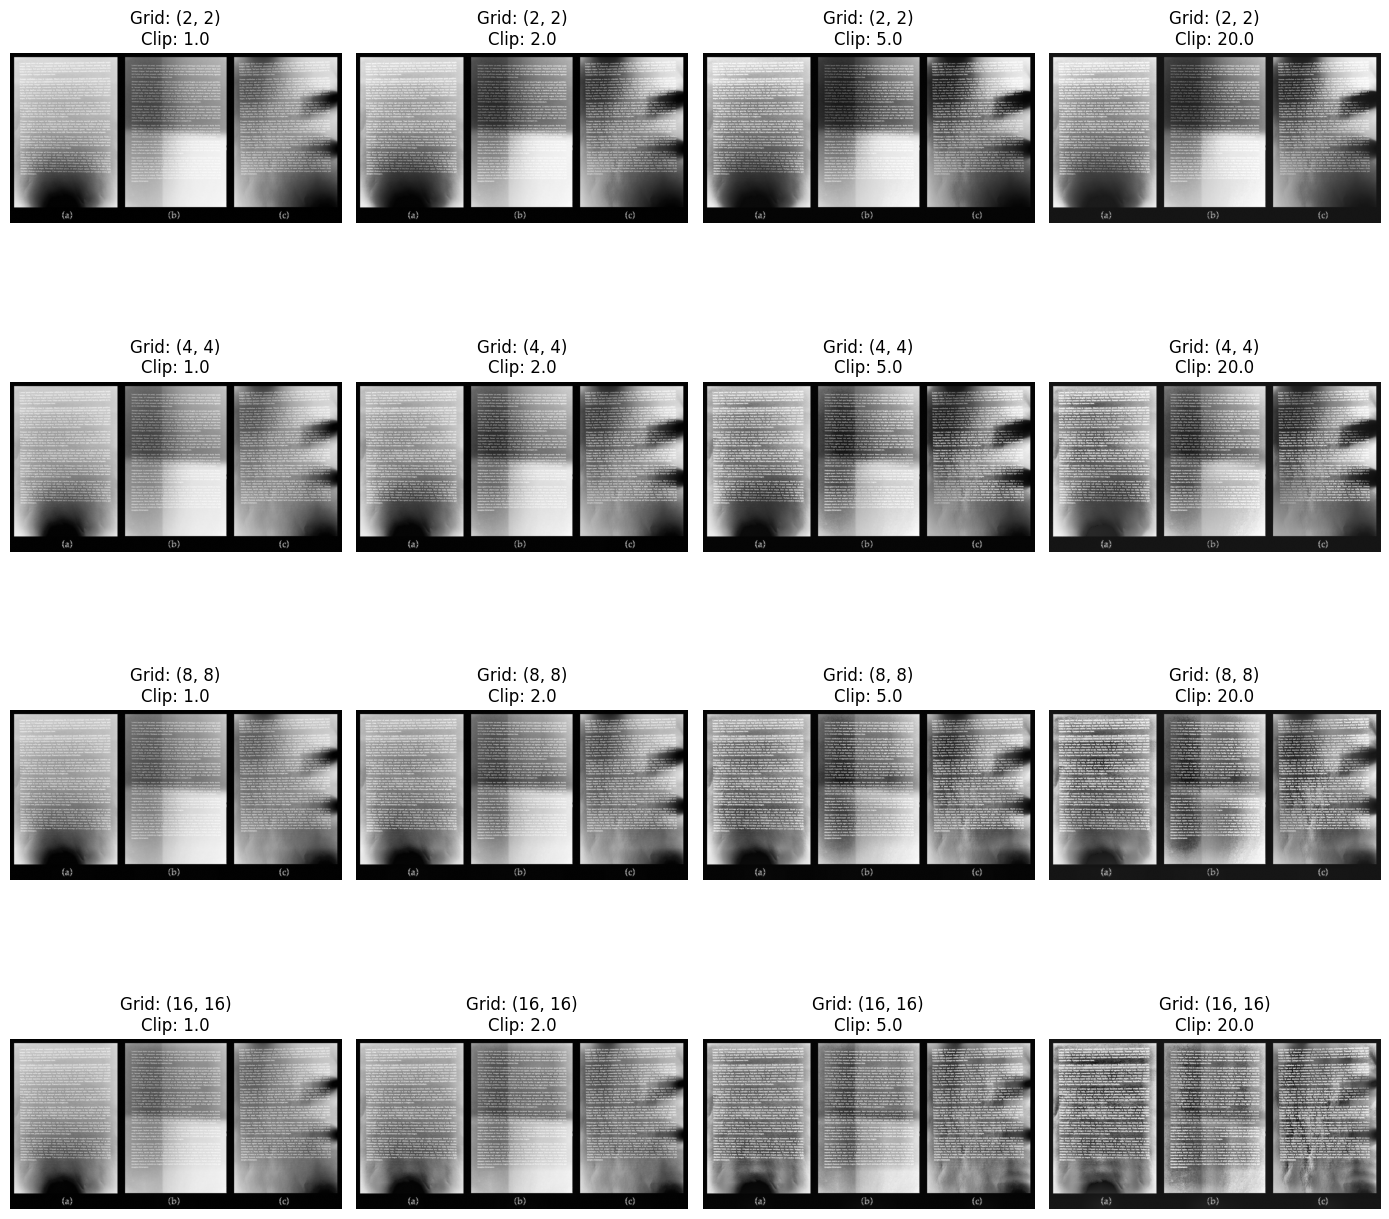

In [4]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("result", exist_ok=True)

grids = [(2, 2), (4, 4), (8, 8), (16, 16)]
clip_limits = [1.0, 2.0, 5.0, 20.0]

fig1, axes1 = plt.subplots(4, 4, figsize=(14, 14))

for i, g in enumerate(grids):
    for j, cl in enumerate(clip_limits):
        # Đã sửa s_max=s thành clip_limit=cl
        out = clahe(img, grid=g, clip_limit=cl)

        name = f"Grid_{g[0]}x{g[1]}_Clip_{cl}.png"
        plt.imsave(f"result/{name}", out, cmap="gray")

        axes1[i, j].imshow(out, cmap="gray")
        axes1[i, j].set_title(f"Grid: {g}\nClip: {cl}")
        axes1[i, j].axis("off")

plt.tight_layout()
plt.show() 


## 2. Yêu cầu (b) — So sánh với thuật toán đã học

Tiến hành hiển thị cạnh nhau kết quả của 4 kỹ thuật xử lý để làm nổi bật sự khác biệt giữa quyết định toàn cục và quyết định thích nghi:

* Kéo giãn tương phản tuyến tính.
* Hiệu chỉnh gamma.
* Cân bằng lược đồ xám toàn cục (HE).
* Cân bằng lược đồ xám thích nghi có giới hạn tương phản (CLAHE).

**Yêu cầu đánh giá:**

* Mỗi ảnh kết quả đầu ra bắt buộc phải đi kèm với lược đồ xám tương ứng để chứng minh sự thay đổi về mặt phân phối mức xám.
* Tìm kiếm và phân tích **một trường hợp tối ưu**: Ảnh đầu vào thể hiện sự vượt trội rõ rệt của CLAHE so với 3 phương pháp còn lại.
* Tìm kiếm và phân tích **một trường hợp thất bại**: Ảnh đầu vào bộc lộ điểm yếu, khiến CLAHE cho ra kết quả thua kém so với một trong các kỹ thuật cơ bản.

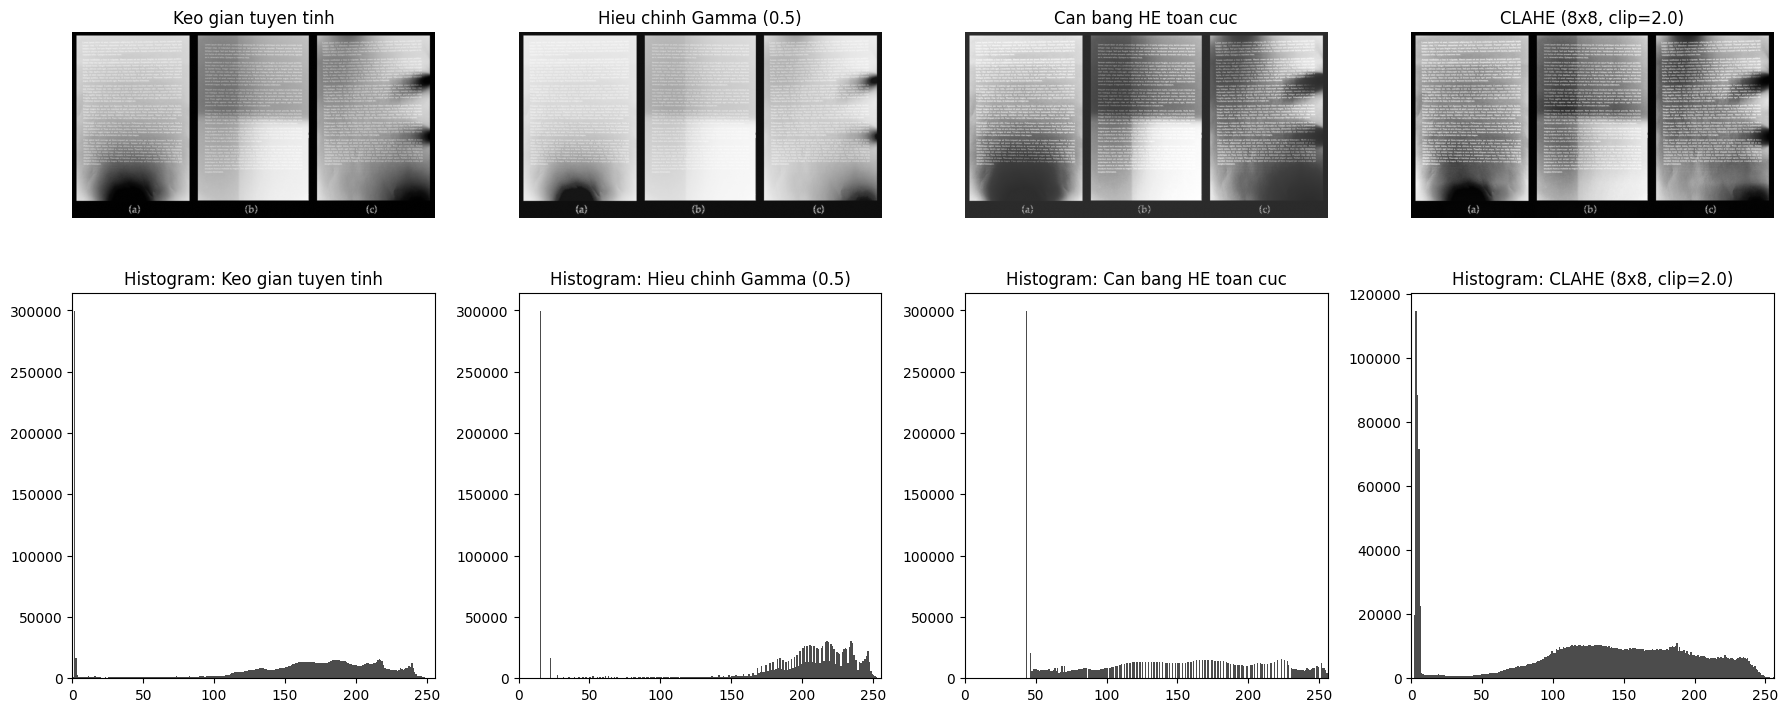

In [5]:
# Keo gian tuong phan tuyen tinh
min_val, max_val = np.min(img), np.max(img)
linear_stretched = ((img - min_val) / (max_val - min_val) * 255.0).astype(np.uint8)

# Gamma correction (gamma = 0.5)
gamma = 0.5
gamma_corrected = np.clip(255.0 * (img / 255.0) ** gamma, 0, 255).astype(np.uint8)

# Can bang luoc do xam toan cuc (Global HE)
hist = np.bincount(img.ravel(), minlength=256)
cdf = np.cumsum(hist)
lut_he = np.round(255.0 * cdf / cdf[-1]).astype(np.uint8)
global_he = lut_he[img]

# CLAHE tu viet
res_clahe = clahe(img, grid=(8, 8), clip_limit=2.0)

methods = [
    ('Keo gian tuyen tinh', linear_stretched),
    ('Hieu chinh Gamma (0.5)', gamma_corrected),
    ('Can bang HE toan cuc', global_he),
    ('CLAHE (8x8, clip=2.0)', res_clahe) # Đã sửa title
]

fig2, axes2 = plt.subplots(2, 4, figsize=(18, 8))
for col, (name, res) in enumerate(methods):
    axes2[0, col].imshow(res, cmap='gray')
    axes2[0, col].set_title(name)
    axes2[0, col].axis('off')
    
    axes2[1, col].hist(res.ravel(), bins=256, range=[0, 256], color='black', alpha=0.7)
    axes2[1, col].set_title(f"Histogram: {name}")
    axes2[1, col].set_xlim([0, 256])

plt.tight_layout()
plt.show()